# Try the model

Talk to the two run-2 models side by side:

- pretrained (`out/pretrain/ckpt.pt`): read 160 M tokens of 19th-century Portuguese, never saw Machado
- fine-tuned (`out/finetune/ckpt.pt`): the same weights after fine-tuning on Machado (best checkpoint, step 650)

Both use the same tokenizer (`data/pretrain/tokenizer.json`). Run the cells top to bottom; change the
prompts in section 2. The library page for this notebook is [`docs/06b-run2-log.md`](../docs/06b-run2-log.md).

> Machado's edition spells her *Capitú* (with the accent). "Capitu" is tokenized differently and
> points the model at *Capítulo*.


In [1]:
import os, sys
import torch
import matplotlib.pyplot as plt

# Run from the repo root so the project's modules and paths resolve.
if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")
sys.path.insert(0, os.getcwd())

from config import ModelConfig
from model import TinyGPT
from tokenizer import BPETokenizer
from train import pick_device

device = pick_device()
tok = BPETokenizer.load("data/pretrain/tokenizer.json")

def load(path):
    ckpt = torch.load(path, map_location=device)
    model = TinyGPT(ModelConfig(**ckpt["model_config"])).to(device)
    model.load_state_dict(ckpt["model"])
    model.eval()
    print(f"{path}: step {ckpt['iter']}, val loss {ckpt['val_loss']:.3f}")
    return model

models = {"pretrained": load("out/pretrain/ckpt.pt"),
          "fine-tuned": load("out/finetune/ckpt.pt")}
print("device:", device)

out/pretrain/ckpt.pt: step 18000, val loss 3.434
out/finetune/ckpt.pt: step 650, val loss 3.143
device: cpu


## 1. How the tokenizer cuts a prompt

The model never sees letters, only these pieces (`␣` = space).

In [2]:
def show_tokens(text):
    print(" | ".join(tok.decode([i]).replace(" ", "␣") for i in tok.encode(text)))

show_tokens("Capitu")
show_tokens("Capitú")
show_tokens("Nem por isso me zanguei.")

C | ap | itu
C | ap | it | ú
N | em | ␣por | ␣isso | ␣me | ␣z | an | gu | ei | .


## 2. Same prompt, same seed, both models

`temperature` < 1 is safer and more repetitive, > 1 wilder; `top_k` keeps only the k most likely tokens
at each step (see [04, Generating text](../docs/04-assembling.md)).

In [3]:
@torch.no_grad()
def sample(model, prompt, n_tokens=100, temperature=0.8, top_k=50, seed=42):
    torch.manual_seed(seed)
    idx = torch.tensor([tok.encode(prompt)], device=device)
    out = model.generate(idx, n_tokens, temperature, top_k, tok.eot_id)
    return tok.decode(out[0].tolist())

def compare(prompt, **kw):
    for name, model in models.items():
        print(f"━━━ {name} ━━━")
        print(sample(model, prompt, **kw), "\n")

compare("Capitú")

━━━ pretrained ━━━


Capitú.

Ai 1

J

.

Ai !

Ai !

Ai !

Thomaz (Piolho)

Calcula-se :

E a gente !

Ai !

E que vé !

Gallieu (Piegas)

Homem !

Meusinha Senhora !

Fora que Violante 

━━━ fine-tuned ━━━


Capitú achou um grande silencio, o mais baixo com a ponta de pedra. Sentou-se nos olhos com os olhos nella. Estacio inclinou-se novamente para ella.

--Que é? perguntou ella sorrindo.

--Não digo nada, disse-lhe então.

--Não; mas o que tem razão me parece?

Luiz Alves approximou-se-lhe.

--Indice 



In [4]:
compare("Nem por isso me zanguei.")

━━━ pretrained ━━━


Nem por isso me zanguei.

Senhor, o mais pequeno com a popa de ferro , que fica próximo do S. Pedro, e do S. João me chamam do Cabo Verde, em cuja rua se está collocada uma grande bainha de agua, que se disparava dos muros que se abriram.

E' que no anno de 1817, que se acham duas léguas de distancia, que corre pelo Pontal para que já se design 

━━━ fine-tuned ━━━


Nem por isso me zanguei.

SCENAII

MARCAVALA

Marianna?

DIOGO

Sim, sim; mas que me faz mal de dizer isto?

MARIA

Talvez a senhora que está tão boa.)

MAGALHÃES

A senhora não me parece?

D. CARLOTA

De que modo?

MARIQUINA 



In [5]:
# Your turn: change the prompt, the seed, the temperature.
compare("Ao verme que primeiro roeu as frias carnes", temperature=0.9, seed=7)

━━━ pretrained ━━━


Ao verme que primeiro roeu as frias carnes que lhe cahiam no leito, com as mãosinhas que enchiam para os altares, quando a velha de um morgado que era da mão, a dos outros e a dos seus criados e dos seus companheiros.

Quando ao meio do quarto da sua avó, os olhos tinham-se rezados, e ao entrar nos salões a casa do Feliciano José de Alcantara, a quem o pae e os filhos deviam 

━━━ fine-tuned ━━━


Ao verme que primeiro roeu as frias carnes,

Jorge, já se foi ás vezes. Quiz ver se o somno lhe désse a vida.

Que um dia, adeus! Quem o amasse? Quincas Benedicto, ao jardim, Em que se lhe lembra o nome, ou o nome No gymnastico, o aspecto Das nuvens de Cypreste, em que a morte Novos e os olhos mortos 



## 3. What does each model expect next?

The model's real output is not text but a probability for each of the 4,096 tokens. Here are the top 8
after one prompt, for both models.

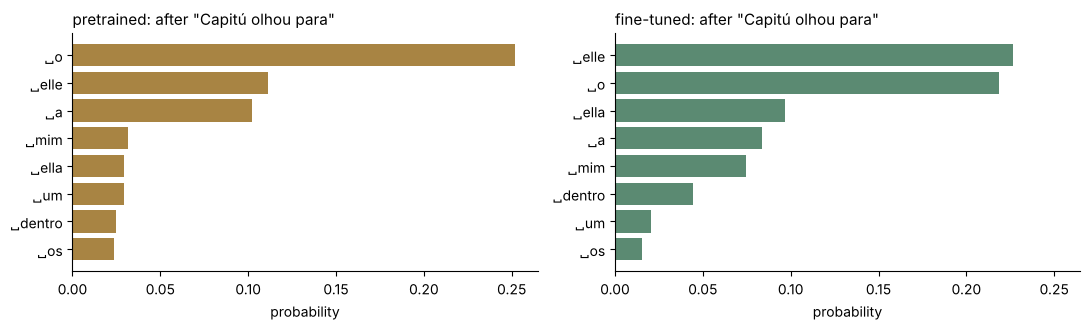

In [6]:
@torch.no_grad()
def next_token_probs(model, prompt, k=8):
    idx = torch.tensor([tok.encode(prompt)], device=device)
    logits, _ = model(idx)
    p = torch.softmax(logits[0, -1].float(), dim=-1)
    v, i = p.topk(k)
    return [tok.decode([j]).replace(" ", "␣") for j in i.tolist()], v.tolist()

prompt = "Capitú olhou para"
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4), sharex=True)
for ax, (name, model), color in zip(axes, models.items(), ["#A88443", "#5B8A72"]):
    labels, probs = next_token_probs(model, prompt)
    ax.barh(labels[::-1], probs[::-1], color=color)
    ax.set_title(f"{name}: after \"{prompt}\"", loc="left", fontsize=11)
    ax.set_xlabel("probability")
    for s in ["top", "right"]:
        ax.spines[s].set_visible(False)
plt.tight_layout()

## 4. Where does the fine-tuned model look?

Attention weights of the last block, one heatmap per head (row = the token looking, column = the token
looked at). Same code as `scripts/attention_maps.py`.

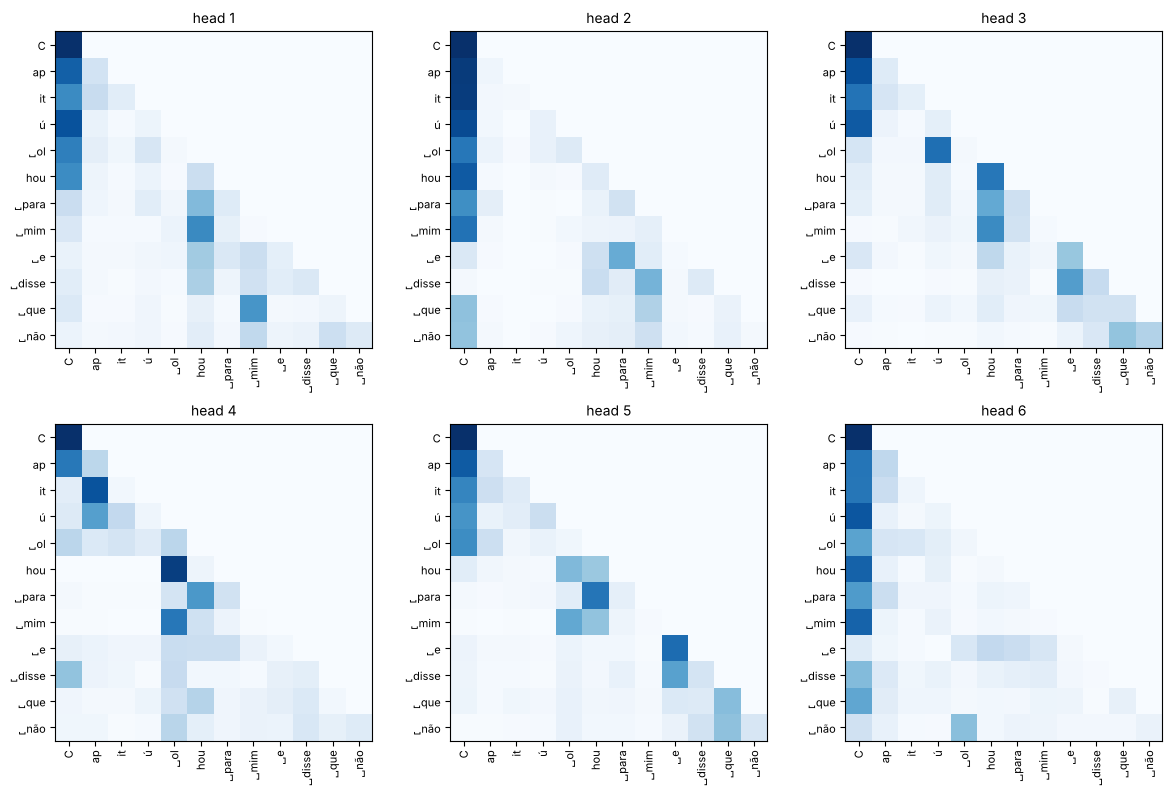

In [7]:
sys.path.insert(0, "scripts")
from attention_maps import attention_weights
%matplotlib inline
# (attention_maps.py switches matplotlib to file output; this switches it back)

sentence = "Capitú olhou para mim e disse que não"
ids = tok.encode(sentence)
labels = [tok.decode([i]).replace(" ", "␣") for i in ids]
maps = attention_weights(models["fine-tuned"].cpu(), torch.tensor([ids]))
models["fine-tuned"].to(device)

w = maps[-1]   # last block: (heads, T, T)
fig, axes = plt.subplots(2, 3, figsize=(12, 8))
for h, ax in enumerate(axes.flat):
    ax.imshow(w[h], cmap="Blues", vmin=0, vmax=1)
    ax.set_title(f"head {h + 1}", fontsize=10)
    ax.set_xticks(range(len(ids)), labels, rotation=90, fontsize=8)
    ax.set_yticks(range(len(ids)), labels, fontsize=8)
plt.tight_layout()